# Sprint 7 – Notebook 5: Logistic Regression
 
 Dataset selected: Telco Customer Churn

# 1. Introduction

Logistic Regression is a supervised machine learning algorithm used for classification.

It predicts the probability that an observation belongs to a particular class.

In this notebook, we use customer information to predict whether a customer will leave a telecom service or continue using it.

Objective:
- Understand Logistic Regression.
- Learn binary and multiclass classification.
- Understand sigmoid function and probability.
- Understand decision boundary and threshold.
- Implement Logistic Regression using Scikit-learn.
- Evaluate the classification model.

# 2. Import Required Libraries

Explanation: Import the Python libraries required for data analysis, visualization, preprocessing, model building, and evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    log_loss,
    roc_auc_score,
    roc_curve
)

from sklearn.datasets import load_iris

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")


Libraries imported successfully!


# 3. Load the Dataset

Explanation: Load the downloaded Telco Customer Churn CSV file into a Pandas DataFrame.

Make sure the CSV file is in the same folder as your notebook. If it is inside another folder, update the file path.

In [9]:

df = pd.read_csv(r"datasets/Telco_customer_churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# 4. Dataset Overview

Explanation: Display the first five records, last five records, and dataset dimensions.

In [10]:
print("First 5 Rows:")
display(df.head())

print("Last 5 Rows:")
display(df.tail())

print("Dataset Shape:", df.shape)


First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Last 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


Dataset Shape: (7043, 21)


# 6. What is Classification?

Classification is a supervised machine learning technique used to predict categories or class labels.

Examples:
- Email: Spam or Not Spam.
- Customer: Churned or Not Churned.
- Medical result: Positive or Negative.

There are two main types:

1. Binary Classification
2. Multiclass Classification
7. Binary Classification

Explanation:

Binary classification predicts one of two possible classes.

In our Customer Churn dataset:
- 0 = No (Customer stayed)
- 1 = Yes (Customer left)

In [11]:
print("Churn Categories:")
print(df["Churn"].value_counts())

print("\nChurn Percentages:")
print(df["Churn"].value_counts(normalize=True) * 100)


Churn Categories:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentages:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


Interpretation: The dataset contains customers who stayed and customers who left the telecom service.

# 8. What is Logistic Regression?

Logistic Regression is a supervised machine learning algorithm used mainly for classification problems.

It predicts the probability of an observation belonging to a class.

Despite its name, Logistic Regression is a classification algorithm because it predicts class probabilities and assigns class labels using a threshold.

Why is it called Logistic Regression?

It uses a logistic (sigmoid) function to convert a mathematical score into a probability between 0 and 1.

# 9. Sigmoid Function

The sigmoid function converts any real-valued input into a probability between 0 and 1.

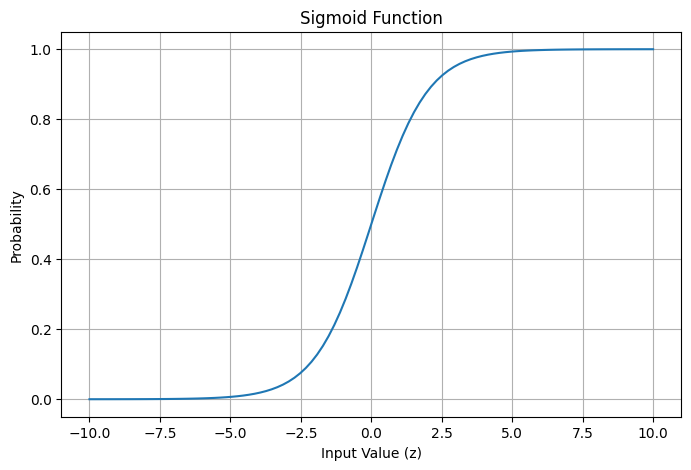

In [12]:
z = np.linspace(-10, 10, 100)

sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid)

plt.title("Sigmoid Function")
plt.xlabel("Input Value (z)")
plt.ylabel("Probability")
plt.grid(True)
plt.show()


Interpretation: The sigmoid curve converts input values into probabilities between 0 and 1.

# 10. Probability

Probability represents the likelihood of an event happening.

In Customer Churn Prediction:
- Probability close to 0 means the customer is less likely to leave.
- Probability close to 1 means the customer is more likely to leave.

In [13]:

probabilities = [0.10, 0.30, 0.50, 0.70, 0.90]

for p in probabilities:
    print(f"Probability: {p}")


Probability: 0.1
Probability: 0.3
Probability: 0.5
Probability: 0.7
Probability: 0.9


# 11. Decision Boundary

A decision boundary is the dividing line or surface that separates different predicted classes.

In binary Logistic Regression, the default decision boundary is usually probability 0.5

- Probability below 0.5 → Class 0.
- Probability equal to or above 0.5 → Class 1.

In [14]:
sample_probabilities = np.array([0.20, 0.40, 0.60, 0.80])

predicted_classes = (sample_probabilities >= 0.5).astype(int)

print("Probabilities:", sample_probabilities)
print("Predicted Classes:", predicted_classes)


Probabilities: [0.2 0.4 0.6 0.8]
Predicted Classes: [0 0 1 1]


# 13. Data Preparation

Prepare the dataset before training the Logistic Regression model.

We will:

- Convert TotalCharges into numeric format.
- Remove customerID because it is only an identification column.
- Convert Churn into binary values.
- Separate input features and target variable.

In [15]:
# Convert TotalCharges into numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Remove customerID
df = df.drop("customerID", axis=1)

# Convert Churn into binary values
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Separate features and target
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Values:")
print(y.value_counts())


Features Shape: (7043, 19)
Target Shape: (7043,)

Target Values:
Churn
0    5174
1    1869
Name: count, dtype: int64


Interpretation: The target variable now contains 0 and 1 instead of No and Yes.

# 14. Train-Test Split

Train-test split divides the dataset into two parts.
- Training data: Used to train the model.
- Testing data: Used to evaluate model performance.

We use 80% for training and 20% for testing.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape: (5634, 19)
Testing Data Shape: (1409, 19)


# 15. Data Preprocessing Pipeline

Preprocessing prepares numerical and categorical data for machine learning.

Numerical features:
- Missing values are filled using median.
- StandardScaler standardizes the values.

Categorical features:

- Missing values are filled using the most frequent value.
- OneHotEncoder converts categories into numerical columns.

In [17]:

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))


Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Now create preprocessing pipelines.

In [18]:

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


# 16. Build Logistic Regression Model

Create a machine learning pipeline that combines preprocessing and Logistic Regression.

max_iter=1000 allows the model enough iterations to converge.

In [19]:

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Logistic Regression model created successfully!")


Logistic Regression model created successfully!


# 17. Train the Model

Train the Logistic Regression model using training data.

The model learns relationships between customer information and churn status.

In [20]:

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


# 18. Predictions and Probabilities

Use the trained model to predict whether customers will leave or stay.

predict() returns class predictions, while predict_proba() returns probabilities for each class.

In [21]:
y_pred = logistic_model.predict(X_test)

y_probability = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 Predictions:")
print(y_pred[:10])

print("\nFirst 10 Churn Probabilities:")
print(y_probability[:10])


First 10 Predictions:
[0 1 0 0 0 1 0 0 0 0]

First 10 Churn Probabilities:
[0.04529387 0.68441126 0.05872074 0.40170424 0.02154772 0.60393536
 0.44922498 0.13005522 0.00288077 0.39517899]


# 19. Model Evaluation

Evaluate the model using the following classification metrics.

- Accuracy: Overall percentage of correct predictions.
- Precision: How many predicted churn customers actually churned.
- Recall: How many actual churn customers were correctly identified.
- F1-score: Balance between precision and recall.
- ROC-AUC: Measures how well the model separates the two classes.

In [22]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("ROC-AUC Score:", roc_auc)


Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1 Score: 0.6040462427745664
ROC-AUC Score: 0.8418610659019866


Interpretation: Higher scores generally indicate better classification performance. Consider precision and recall together because missing customers who are likely to leave can be important for a business.

# 20. Confusion Matrix and Classification Report

A confusion matrix compares actual and predicted classes.

It contains:
- True Positive (TP)
- True Negative (TN)
- False Positive (FP)
- False Negative (FN)

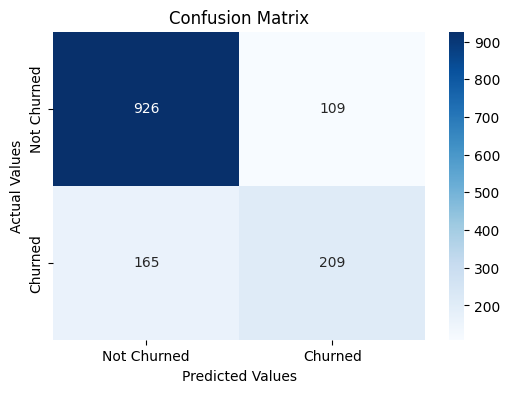


Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [23]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Churned", "Churned"],
    yticklabels=["Not Churned", "Churned"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Interpretation: The confusion matrix helps us understand correct and incorrect predictions for each customer category.

# 21. Log Loss

Log Loss measures how well a classification model predicts probabilities.

- Lower Log Loss indicates better probability predictions.
- Higher Log Loss indicates poorer probability predictions.
- A confident incorrect prediction receives a larger penalty.

In [24]:

loss = log_loss(y_test, y_probability)

print("Log Loss:", loss)


Log Loss: 0.4205215677474423


Interpretation: A lower Log Loss indicates that the predicted probabilities are closer to the actual outcomes.

# 22. ROC Curve

ROC stands for Receiver Operating Characteristic.

The ROC curve shows the relationship between:
- True Positive Rate
- False Positive Rate
A higher ROC-AUC score generally indicates better class separation.

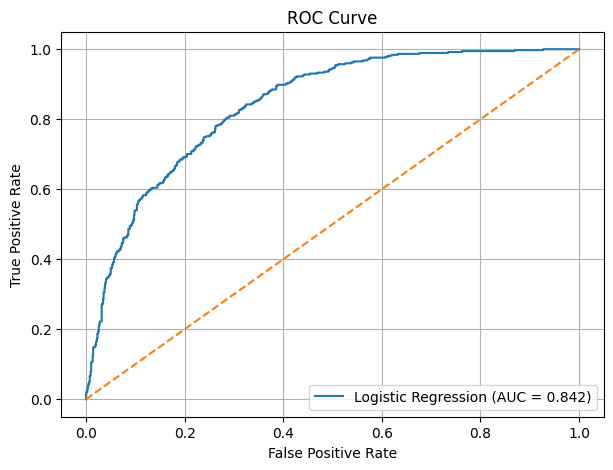

In [25]:

fpr, tpr, thresholds = roc_curve(y_test, y_probability)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()


# 23. Coefficients and Intercept

Coefficients show how input features influence the model's prediction.
- Positive coefficient: Increases the predicted likelihood of churn.
- Negative coefficient: Decreases the predicted likelihood of churn.

The intercept is the model's baseline score.

In [26]:

trained_classifier = logistic_model.named_steps["classifier"]

feature_names = logistic_model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = trained_classifier.coef_[0]

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

print("Intercept:")
print(trained_classifier.intercept_)

print("\nModel Coefficients:")
display(
    coefficient_df.sort_values(
        by="Coefficient",
        ascending=False
    ).head(15)
)


Intercept:
[-0.57991789]

Model Coefficients:


,Feature,Coefficient
16,cat__InternetService_Fiber optic,0.640026
36,cat__Contract_Month-to-month,0.579304
3,num__TotalCharges,0.516708
35,cat__StreamingMovies_Yes,0.204014
32,cat__StreamingTV_Yes,0.203626
43,cat__PaymentMethod_Electronic check,0.198412
18,cat__OnlineSecurity_No,0.157023
27,cat__TechSupport_No,0.132115
14,cat__MultipleLines_Yes,0.105954
0,num__SeniorCitizen,0.053929


# 24. Coefficient Visualization

Visualize the features with the strongest positive and negative coefficients.

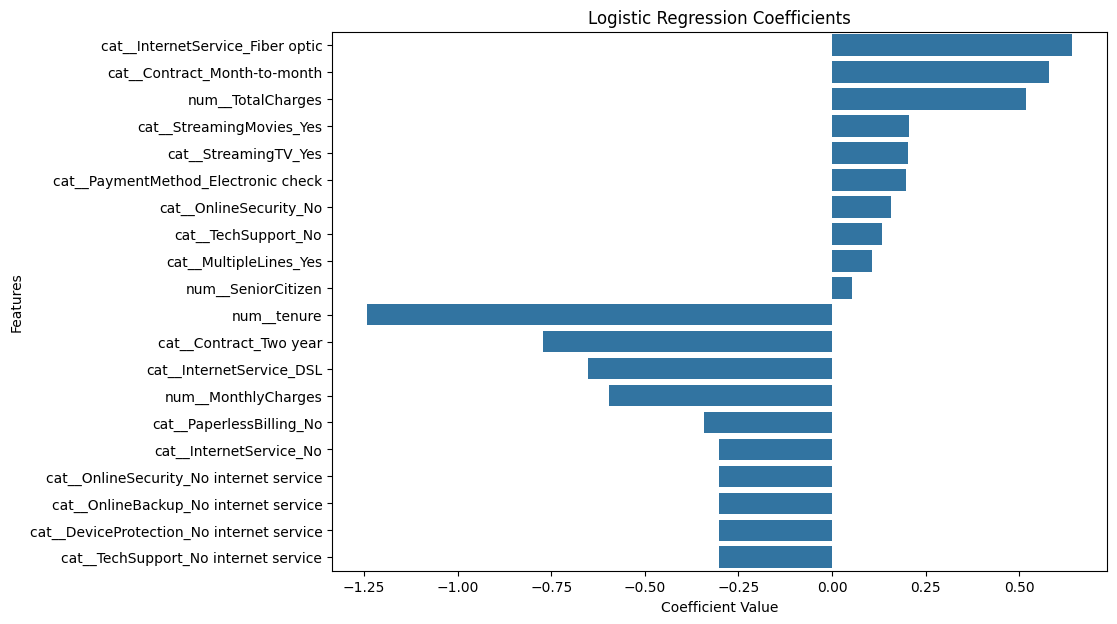

In [27]:

top_positive = coefficient_df.nlargest(10, "Coefficient")
top_negative = coefficient_df.nsmallest(10, "Coefficient")

plot_df = pd.concat([top_positive, top_negative])

plt.figure(figsize=(10, 7))

sns.barplot(
    data=plot_df,
    x="Coefficient",
    y="Feature"
)

plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.show()


Interpretation: This visualization helps identify which features have stronger positive or negative relationships with predicted churn, holding other model inputs constant.

# 25. Threshold Analysis

The default classification threshold is 0.5. We can change it to see how the predictions change.

A lower threshold generally identifies more customers as likely to churn, which may increase recall but reduce precision.

In [28]:

thresholds = [0.3, 0.5, 0.7]

for threshold in thresholds:

    threshold_pred = (
        y_probability >= threshold
    ).astype(int)

    print("\nThreshold:", threshold)

    print(
        "Accuracy:",
        accuracy_score(y_test, threshold_pred)
    )

    print(
        "Precision:",
        precision_score(
            y_test, threshold_pred, zero_division=0
        )
    )

    print(
        "Recall:",
        recall_score(
            y_test, threshold_pred, zero_division=0
        )
    )



Threshold: 0.3
Accuracy: 0.7494677075940384
Precision: 0.5193370165745856
Recall: 0.7540106951871658

Threshold: 0.5
Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647

Threshold: 0.7
Accuracy: 0.765791341376863
Precision: 0.7391304347826086
Recall: 0.18181818181818182


Interpretation: Threshold selection depends on the business objective. For customer churn, a business may prefer higher recall to identify more customers who might leave.

# 26. Multiclass Classification

Multiclass classification predicts one category from three or more possible categories.

Examples:
- Predicting flower types.
- Classifying animals.
- Identifying different product categories.
For this demonstration, we use the built-in Iris dataset.

The Iris dataset contains three flower classes:
- Setosa
- Versicolor
- Virginica

In [29]:

iris = load_iris()

X_iris = iris.data
y_iris = iris.target

print("Iris Dataset Shape:", X_iris.shape)

print("\nFlower Classes:")
print(iris.target_names)


Iris Dataset Shape: (150, 4)

Flower Classes:
['setosa' 'versicolor' 'virginica']


Prepare and split Iris data

In [30]:

X_iris_train, X_iris_test, y_iris_train, y_iris_test = train_test_split(
    X_iris,
    y_iris,
    test_size=0.2,
    random_state=42,
    stratify=y_iris
)

print("Iris training shape:", X_iris_train.shape)
print("Iris testing shape:", X_iris_test.shape)


Iris training shape: (120, 4)
Iris testing shape: (30, 4)


Build and train multiclass Logistic Regression

In [31]:

iris_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

iris_model.fit(X_iris_train, y_iris_train)

print("Multiclass Logistic Regression trained successfully!")


Multiclass Logistic Regression trained successfully!


Make multiclass predictions

In [32]:

iris_pred = iris_model.predict(X_iris_test)

iris_accuracy = accuracy_score(
    y_iris_test,
    iris_pred
)

print("Multiclass Accuracy:", iris_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_iris_test,
        iris_pred,
        target_names=iris.target_names
    )
)


Multiclass Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



Interpretation: The model predicts one of three flower categories instead of only two classes.

# 27. Final Prediction Table

Create a table comparing actual churn values with predicted churn values and predicted probabilities.

In [33]:

results = pd.DataFrame({
    "Actual Churn": y_test.values[:15],
    "Predicted Churn": y_pred[:15],
    "Churn Probability": y_probability[:15]
})

results["Actual Status"] = results["Actual Churn"].map({
    0: "Not Churned",
    1: "Churned"
})

results["Predicted Status"] = results["Predicted Churn"].map({
    0: "Not Churned",
    1: "Churned"
})

display(results)


,Actual Churn,Predicted Churn,Churn Probability,Actual Status,Predicted Status
0,0,0,0.045294,Not Churned,Not Churned
1,0,1,0.684411,Not Churned,Churned
2,0,0,0.058721,Not Churned,Not Churned
3,0,0,0.401704,Not Churned,Not Churned
4,0,0,0.021548,Not Churned,Not Churned
5,0,1,0.603935,Not Churned,Churned
6,0,0,0.449225,Not Churned,Not Churned
7,0,0,0.130055,Not Churned,Not Churned
8,0,0,0.002881,Not Churned,Not Churned
9,1,0,0.395179,Churned,Not Churned
